task1:
Download a sample sales dataset (for example, from Kaggle or use a small CSV you create) with columns like product, category, date, and sales amount. Load it into a Pandas DataFrame and display the first 5 rows to verify the data.


In [1]:
import pandas as pd

data = {
    "product": ["Mobile", "Shirt", "Rice", "Laptop", "Shoes",
                "Mobile", "Shirt", "Rice", "Laptop", "Shoes",
                "Mobile", "Shirt"],
    "category": ["Electronics", "Clothing", "Groceries", "Electronics",
                 "Clothing", "Electronics", "Clothing", "Groceries",
                 "Electronics", "Clothing", "Electronics", "Clothing"],
    "date": ["2026-01-10", "2026-01-15", "2026-02-05", "2026-02-12",
             "2026-03-08", "2026-03-15", "2026-04-02", "2026-04-10",
             "2026-05-05", "2026-05-12", "2026-06-08", "2026-06-15"],
    "sales": [25000, 1500, 800, 55000, 2500, 30000,
              2000, 1000, 60000, 3000, 28000, 1800]
}

df = pd.DataFrame(data)
df["date"] = pd.to_datetime(df["date"])

df.to_csv("sales_data.csv", index=False)

print(df.head())

  product     category       date  sales
0  Mobile  Electronics 2026-01-10  25000
1   Shirt     Clothing 2026-01-15   1500
2    Rice    Groceries 2026-02-05    800
3  Laptop  Electronics 2026-02-12  55000
4   Shoes     Clothing 2026-03-08   2500


task2:
Using Matplotlib, create a bar chart that shows total sales for each product category (like 'Electronics', 'Clothing', 'Groceries'), similar to how Flipkart or Myntra might track category performance.


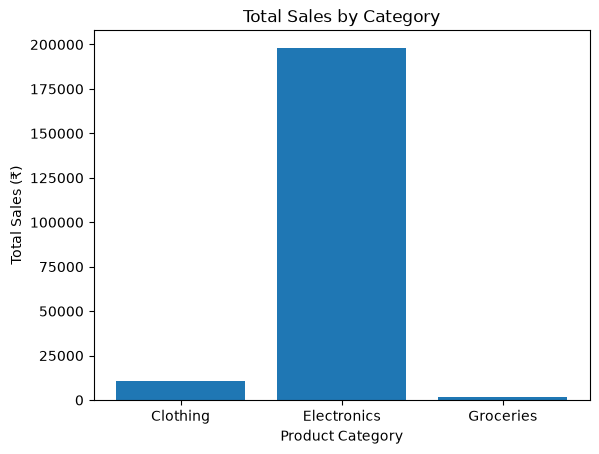

In [2]:
import matplotlib.pyplot as plt

category_sales = df.groupby("category")["sales"].sum()

plt.bar(category_sales.index, category_sales.values)
plt.title("Total Sales by Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales (₹)")
plt.show()

task3:
Plot a line chart to visualize monthly sales trends over a year, using the date column to group sales by month. Add a title and axis labels to make the chart presentation-ready.


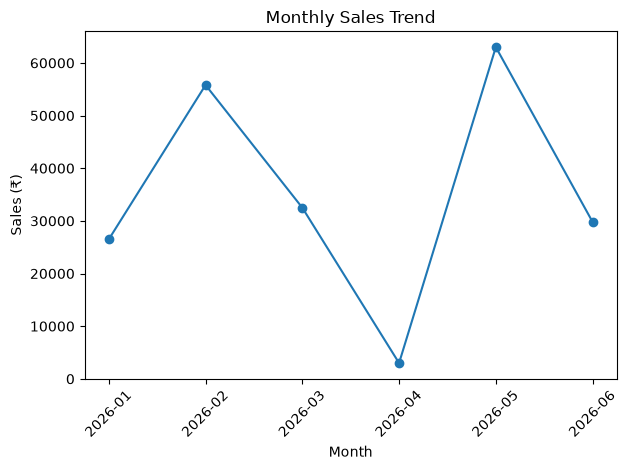

In [3]:
df["month"] = df["date"].dt.to_period("M")

monthly_sales = df.groupby("month")["sales"].sum()

plt.plot(monthly_sales.index.astype(str),
         monthly_sales.values, marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

task4:
Create a histogram to show the distribution of order amounts (sales values), highlighting how many small vs. large purchases happen — like analyzing order size patterns on Zomato or Swiggy.<br><br><em><strong>Hint:</strong> Use plt.hist() and set bins to 10 for a clear distribution.</em>


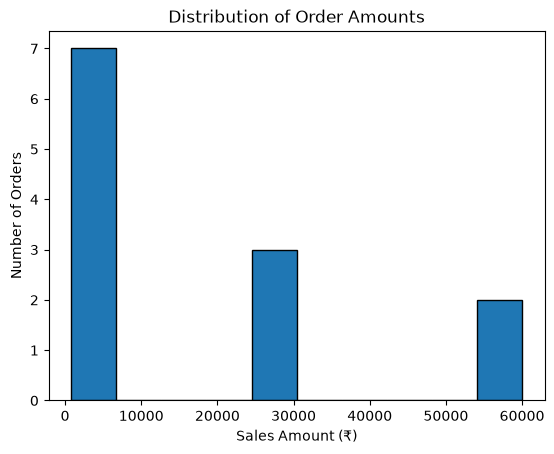

In [4]:
plt.hist(df["sales"], bins=10, edgecolor="black")

plt.title("Distribution of Order Amounts")
plt.xlabel("Sales Amount (₹)")
plt.ylabel("Number of Orders")
plt.show()

task5:
Add value annotations to your category bar chart to display the exact sales amount above each bar, then export the chart as a PNG image file named 'category_sales_kpi.png'.


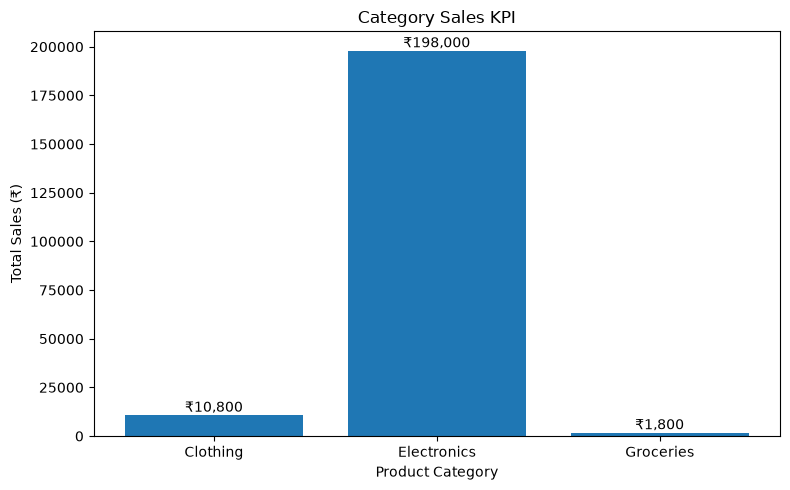

Chart saved successfully!


In [ ]:
category_sales = df.groupby("category")["sales"].sum()

plt.figure(figsize=(8, 5))

bars = plt.bar(category_sales.index, category_sales.values)

plt.title("Category Sales KPI")
plt.xlabel("Product Category")
plt.ylabel("Total Sales (₹)")

for bar in bars:
    value = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"₹{value:,.0f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.savefig("category_sales_kpi.png", dpi=300, bbox_inches="tight")

plt.show()

print("Chart saved successfully!")